## Objective 2 — Linear Regression 2.1
Predicting the Goal Difference in FIFA World Cup 2026 Matches

`Research question:` Can we predict the difference between the home team's goals and the away team's goals using only information available before kickoff?

Assignment requirements

1. 104 rows — one for each supplied match.
2. Exactly 8 explanatory variables (excluding the match ID).
3. Target: goal_difference = home_score - away_score.
4. Linear regression with suitable performance metrics and graphical evaluation.


## 1. Import the libraries

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

np.random.seed(145)

## 2. Load the datasets

In [9]:
matches = pd.read_csv('matches.csv')
teams = pd.read_csv('teams.csv')
venues = pd.read_csv('venues.csv')
stages = pd.read_csv('tournament_stages.csv')

for name, df in [('Matches', matches), ('Teams', teams),
                 ('Venues', venues), ('Stages', stages)]:
    print(f'{name}: {df.shape[0]} rows and {df.shape[1]} columns')

print('\nFirst five match records:')
display(matches.head())

Matches: 104 rows and 17 columns
Teams: 48 rows and 8 columns
Venues: 16 rows and 8 columns
Stages: 7 rows and 3 columns

First five match records:


,match_id,date,kickoff_time_utc,stage_id,venue_id,home_team_id,away_team_id,home_score,away_score,home_penalty_score,away_penalty_score,status,result_type,home_xg,away_xg,referee_id,player_of_the_match_id
0,1,2026-06-11,19:00,1,1,1,2,2,0,NaN,NaN,Completed,Regular,1.84,0.52,2,16
1,2,2026-06-11,23:00,1,7,3,4,2,1,NaN,NaN,Completed,Regular,1.45,1.12,9,58
2,3,2026-06-12,19:00,1,6,5,6,1,1,NaN,NaN,Completed,Regular,1.35,0.98,11,112
3,4,2026-06-12,23:00,1,3,13,14,4,1,NaN,NaN,Completed,Regular,2.76,0.88,12,332
4,5,2026-06-13,15:00,1,15,7,8,1,1,NaN,NaN,Completed,Regular,0.78,1.54,15,157


In [10]:
print('MATCH DATA INFORMATION')
matches.info()
print('\nMissing values in the match dataset:')
print(matches.isnull().sum())
print('\nDescriptive statistics:')
display(matches[['home_score', 'away_score']].describe())

MATCH DATA INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 104 entries, 0 to 103
Data columns (total 17 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   match_id                104 non-null    int64  
 1   date                    104 non-null    object 
 2   kickoff_time_utc        104 non-null    object 
 3   stage_id                104 non-null    int64  
 4   venue_id                104 non-null    int64  
 5   home_team_id            104 non-null    int64  
 6   away_team_id            104 non-null    int64  
 7   home_score              104 non-null    int64  
 8   away_score              104 non-null    int64  
 9   home_penalty_score      3 non-null      float64
 10  away_penalty_score      3 non-null      float64
 11  status                  104 non-null    object 
 12  result_type             104 non-null    object 
 13  home_xg                 104 non-null    float64
 14  away_xg            

,home_score,away_score
count,104.000000,104.000000
mean,1.721154,1.240385
std,1.503761,1.234576
min,0.000000,0.000000
25%,1.000000,0.000000
50%,1.000000,1.000000
75%,3.000000,2.000000
max,7.000000,6.000000


`Intuition:` Missing penalty-shootout scores are expected for matches that did not require a shootout. We do not use those columns for our target. home_score and away_score contain the goals recorded for the match, so our goal difference is calculated without shootout penalties.

We also check that every match can be linked to both teams, its venue and its tournament stage. This prevents accidental loss or duplication of rows during merging.

In [11]:
print('Unique matches:', matches['match_id'].nunique())
print('Duplicate IDs:', matches['match_id'].duplicated().sum())
print('Missing home teams:', (~matches['home_team_id'].isin(teams['team_id'])).sum())
print('Missing away teams:', (~matches['away_team_id'].isin(teams['team_id'])).sum())
print('Missing venues:', (~matches['venue_id'].isin(venues['venue_id'])).sum())
print('Missing stages:', (~matches['stage_id'].isin(stages['stage_id'])).sum())

Unique matches: 104
Duplicate IDs: 0
Missing home teams: 0
Missing away teams: 0
Missing venues: 0
Missing stages: 0


## 3. Data preparation and feature engineering

`Small assumption:` The team Elo ratings have no timestamp in teams.csv. We treat them as pre-match ratings. If they were calculated after a match, they would not be suitable and would need replacement with historical ratings. The FIFA ranking field is explicitly labelled pre-tournament.
This approach uses no player ages, squad aggregation, or complicated feature engineering.

In [12]:
home_teams = teams[['team_id', 'fifa_ranking_pre_tournament', 'elo_rating', 'fifa_code']].rename(columns={
    'team_id': 'home_team_id',
    'fifa_ranking_pre_tournament': 'home_fifa_rank',
    'elo_rating': 'home_elo',
    'fifa_code': 'home_country'
})

away_teams = teams[['team_id', 'fifa_ranking_pre_tournament', 'elo_rating', 'fifa_code']].rename(columns={
    'team_id': 'away_team_id',
    'fifa_ranking_pre_tournament': 'away_fifa_rank',
    'elo_rating': 'away_elo',
    'fifa_code': 'away_country'
})

display(home_teams.head())

,home_team_id,home_fifa_rank,home_elo,home_country
0,1,14,1810,MEX
1,2,60,1620,RSA
2,3,22,1800,KOR
3,4,40,1740,CZE
4,5,33,1795,CAN


In [13]:
data_full = (matches
    .merge(home_teams, on='home_team_id', validate='many_to_one')
    .merge(away_teams, on='away_team_id', validate='many_to_one')
    .merge(venues[['venue_id', 'country', 'capacity', 'elevation_meters']],
           on='venue_id', validate='many_to_one')
    .merge(stages[['stage_id', 'is_knockout']],
           on='stage_id', validate='many_to_one'))

print('Matches after joining:', len(data_full))
assert len(data_full) == 104
assert data_full['match_id'].is_unique

Matches after joining: 104


In [14]:
data_full['host_advantage'] = (
    (data_full['home_country'] == data_full['country']).astype(int)
    - (data_full['away_country'] == data_full['country']).astype(int)
)
data_full['stadium_capacity'] = data_full['capacity']
data_full['stadium_elevation'] = data_full['elevation_meters']
data_full['knockout_match'] = data_full['is_knockout'].astype(int)

# Goal difference is our TARGET, not a predictor.
data_full['goal_difference'] = data_full['home_score'] - data_full['away_score']

feature_cols = [
    'home_fifa_rank', 'away_fifa_rank',
    'home_elo', 'away_elo',
    'host_advantage', 'stadium_capacity',
    'stadium_elevation', 'knockout_match'
]

data = data_full[['match_id'] + feature_cols + ['goal_difference']].copy()
data = data.sort_values('match_id').reset_index(drop=True)

assert len(feature_cols) == 8
assert data.shape == (104, 10)
print('Final dataset shape:', data.shape)
display(data.head())

Final dataset shape: (104, 10)


,match_id,home_fifa_rank,away_fifa_rank,home_elo,away_elo,host_advantage,stadium_capacity,stadium_elevation,knockout_match,goal_difference
0,1,14,60,1810,1620,1,80824,2200,0,2
1,2,22,40,1800,1740,0,48070,1566,0,1
2,3,33,64,1795,1645,1,30000,76,0,0
3,4,17,54,1850,1725,1,70240,30,0,3
4,5,56,19,1600,1860,0,68500,8,0,0


In [15]:
print('Missing values in the final dataset:')
print(data.isnull().sum())
print('\nDuplicate match IDs:', data['match_id'].duplicated().sum())
print('\nFeature types:')
print(data.dtypes)
print('\nStatistical summary:')
display(data.describe().T)

data.to_csv('linear_regression_2_1_simplified_dataset.csv', index=False)
print('\nSaved: linear_regression_2_1_simplified_dataset.csv')

Missing values in the final dataset:
match_id             0
home_fifa_rank       0
away_fifa_rank       0
home_elo             0
away_elo             0
host_advantage       0
stadium_capacity     0
stadium_elevation    0
knockout_match       0
goal_difference      0
dtype: int64

Duplicate match IDs: 0

Feature types:
match_id             int64
home_fifa_rank       int64
away_fifa_rank       int64
home_elo             int64
away_elo             int64
host_advantage       int64
stadium_capacity     int64
stadium_elevation    int64
knockout_match       int64
goal_difference      int64
dtype: object

Statistical summary:


,count,mean,std,min,25%,50%,75%,max
match_id,104.0,52.500000,30.166206,1.0,26.75,52.5,78.25,104.0
home_fifa_rank,104.0,24.759615,22.219774,1.0,6.00,17.0,39.00,85.0
away_fifa_rank,104.0,31.759615,23.219717,1.0,11.00,25.5,51.00,85.0
home_elo,104.0,1867.980769,172.016198,1510.0,1740.00,1850.0,2010.00,2150.0
away_elo,104.0,1810.961538,159.524592,1510.0,1687.50,1797.5,1920.00,2150.0
host_advantage,104.0,0.067308,0.348768,-1.0,0.00,0.0,0.00,1.0
stadium_capacity,104.0,67521.673077,11979.139474,30000.0,64767.00,69796.0,73269.00,82500.0
stadium_elevation,104.0,259.663462,538.322775,2.0,7.75,30.0,264.00,2200.0
knockout_match,104.0,0.307692,0.463774,0.0,0.00,0.0,1.00,1.0
goal_difference,104.0,0.480769,2.024034,-4.0,-1.00,0.0,2.00,6.0



Saved: linear_regression_2_1_simplified_dataset.csv


## 4. Exploratory Data Analysis (EDA)

A goal difference of 0 indicates a draw, a positive value indicates a home-team victory and a negative value indicates an away-team victory. Let's examine the target before training our model.

In [16]:
print('Goal difference distribution:')
print(data['goal_difference'].value_counts().sort_index())

plot_data = data.copy()
plot_data['match_stage'] = np.where(
    plot_data['knockout_match'] == 1, 'Knockout', 'Group'
)
plot_data['match_outcome'] = np.select(
    [plot_data['goal_difference'] > 0, plot_data['goal_difference'] < 0],
    ['Home win', 'Away win'], default='Draw'
)
print('\nMatch outcomes:')
print(plot_data['match_outcome'].value_counts())

Goal difference distribution:
goal_difference
-4     2
-3     6
-2     8
-1    14
 0    24
 1    21
 2    15
 3     7
 4     3
 5     2
 6     2
Name: count, dtype: int64

Match outcomes:
match_outcome
Home win    50
Away win    30
Draw        24
Name: count, dtype: int64


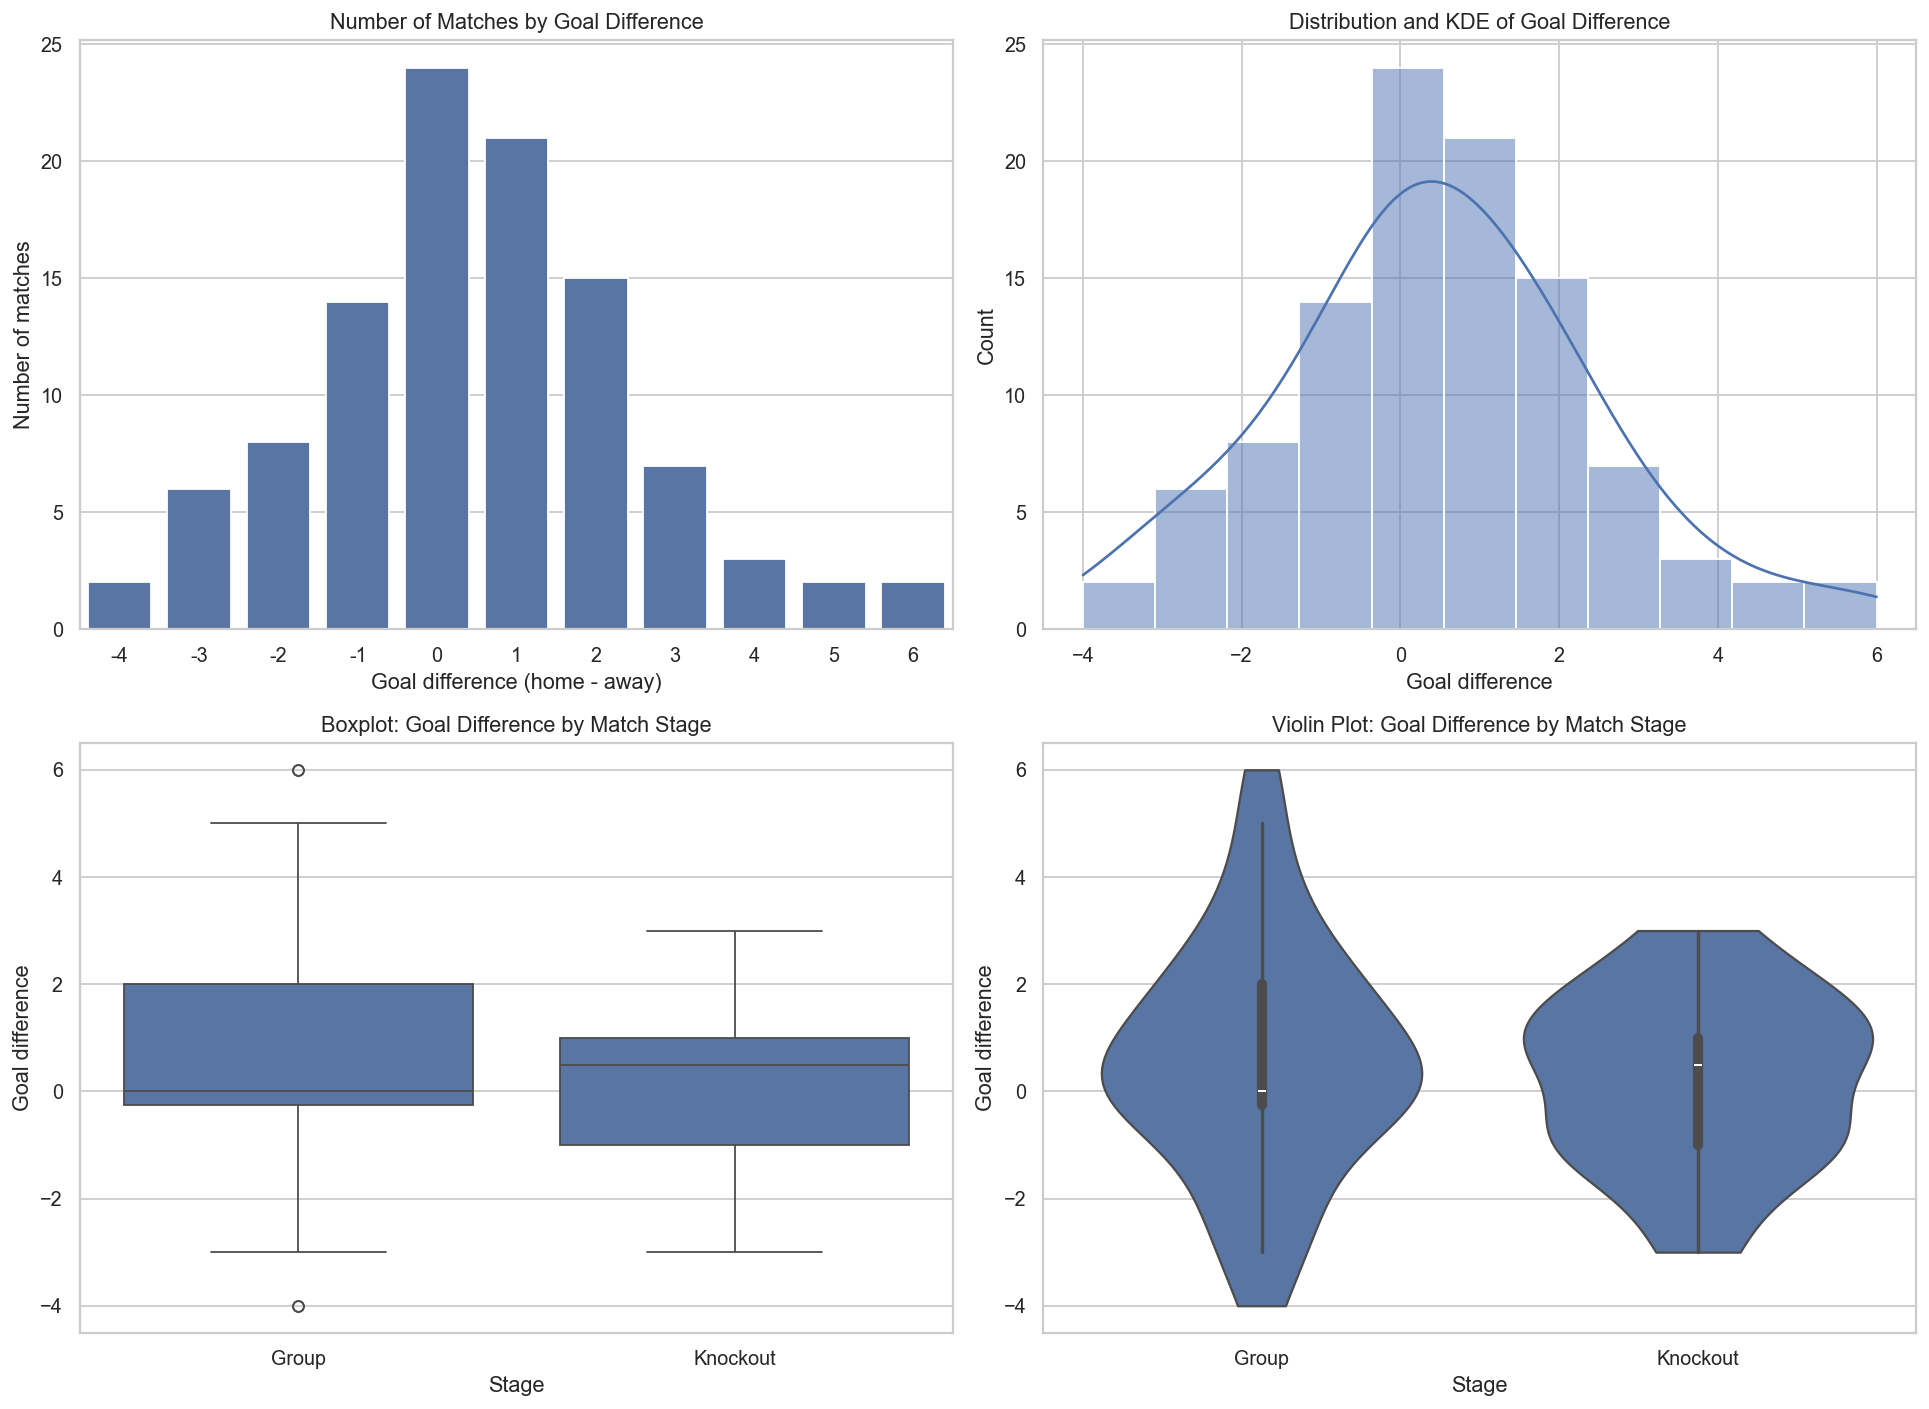

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11), dpi=130)

sns.countplot(data=plot_data, x='goal_difference', color=sns.color_palette()[0],
              order=sorted(plot_data['goal_difference'].unique()), ax=axes[0, 0])
axes[0, 0].set_title('Number of Matches by Goal Difference')
axes[0, 0].set_xlabel('Goal difference (home - away)')
axes[0, 0].set_ylabel('Number of matches')

sns.histplot(data=plot_data, x='goal_difference', bins=11, kde=True, color=sns.color_palette()[0],
             ax=axes[0, 1])
axes[0, 1].set_title('Distribution and KDE of Goal Difference')
axes[0, 1].set_xlabel('Goal difference')

sns.boxplot(data=plot_data, x='match_stage', y='goal_difference', color=sns.color_palette()[0], ax=axes[1, 0])
axes[1, 0].set_title('Boxplot: Goal Difference by Match Stage')
axes[1, 0].set_xlabel('Stage')
axes[1, 0].set_ylabel('Goal difference')

sns.violinplot(data=plot_data, x='match_stage', y='goal_difference', color=sns.color_palette()[0],
               inner='box', cut=0, ax=axes[1, 1])
axes[1, 1].set_title('Violin Plot: Goal Difference by Match Stage')
axes[1, 1].set_xlabel('Stage')
axes[1, 1].set_ylabel('Goal difference')

plt.tight_layout()
plt.show()

`Intuition:` In the 104 provided matches, 50 were home wins, 30 were away wins and 24 were draws (approximately 48.1%, 28.8% and 23.1%). The median goal difference is 0. Group-stage matches (72) have an average goal difference of +0.60, compared with +0.22 in knockout matches (32). The boxplot illustrates the central range and possible outliers; the violin plot illustrates the distribution. These descriptive differences do not establish that tournament stage caused the results.

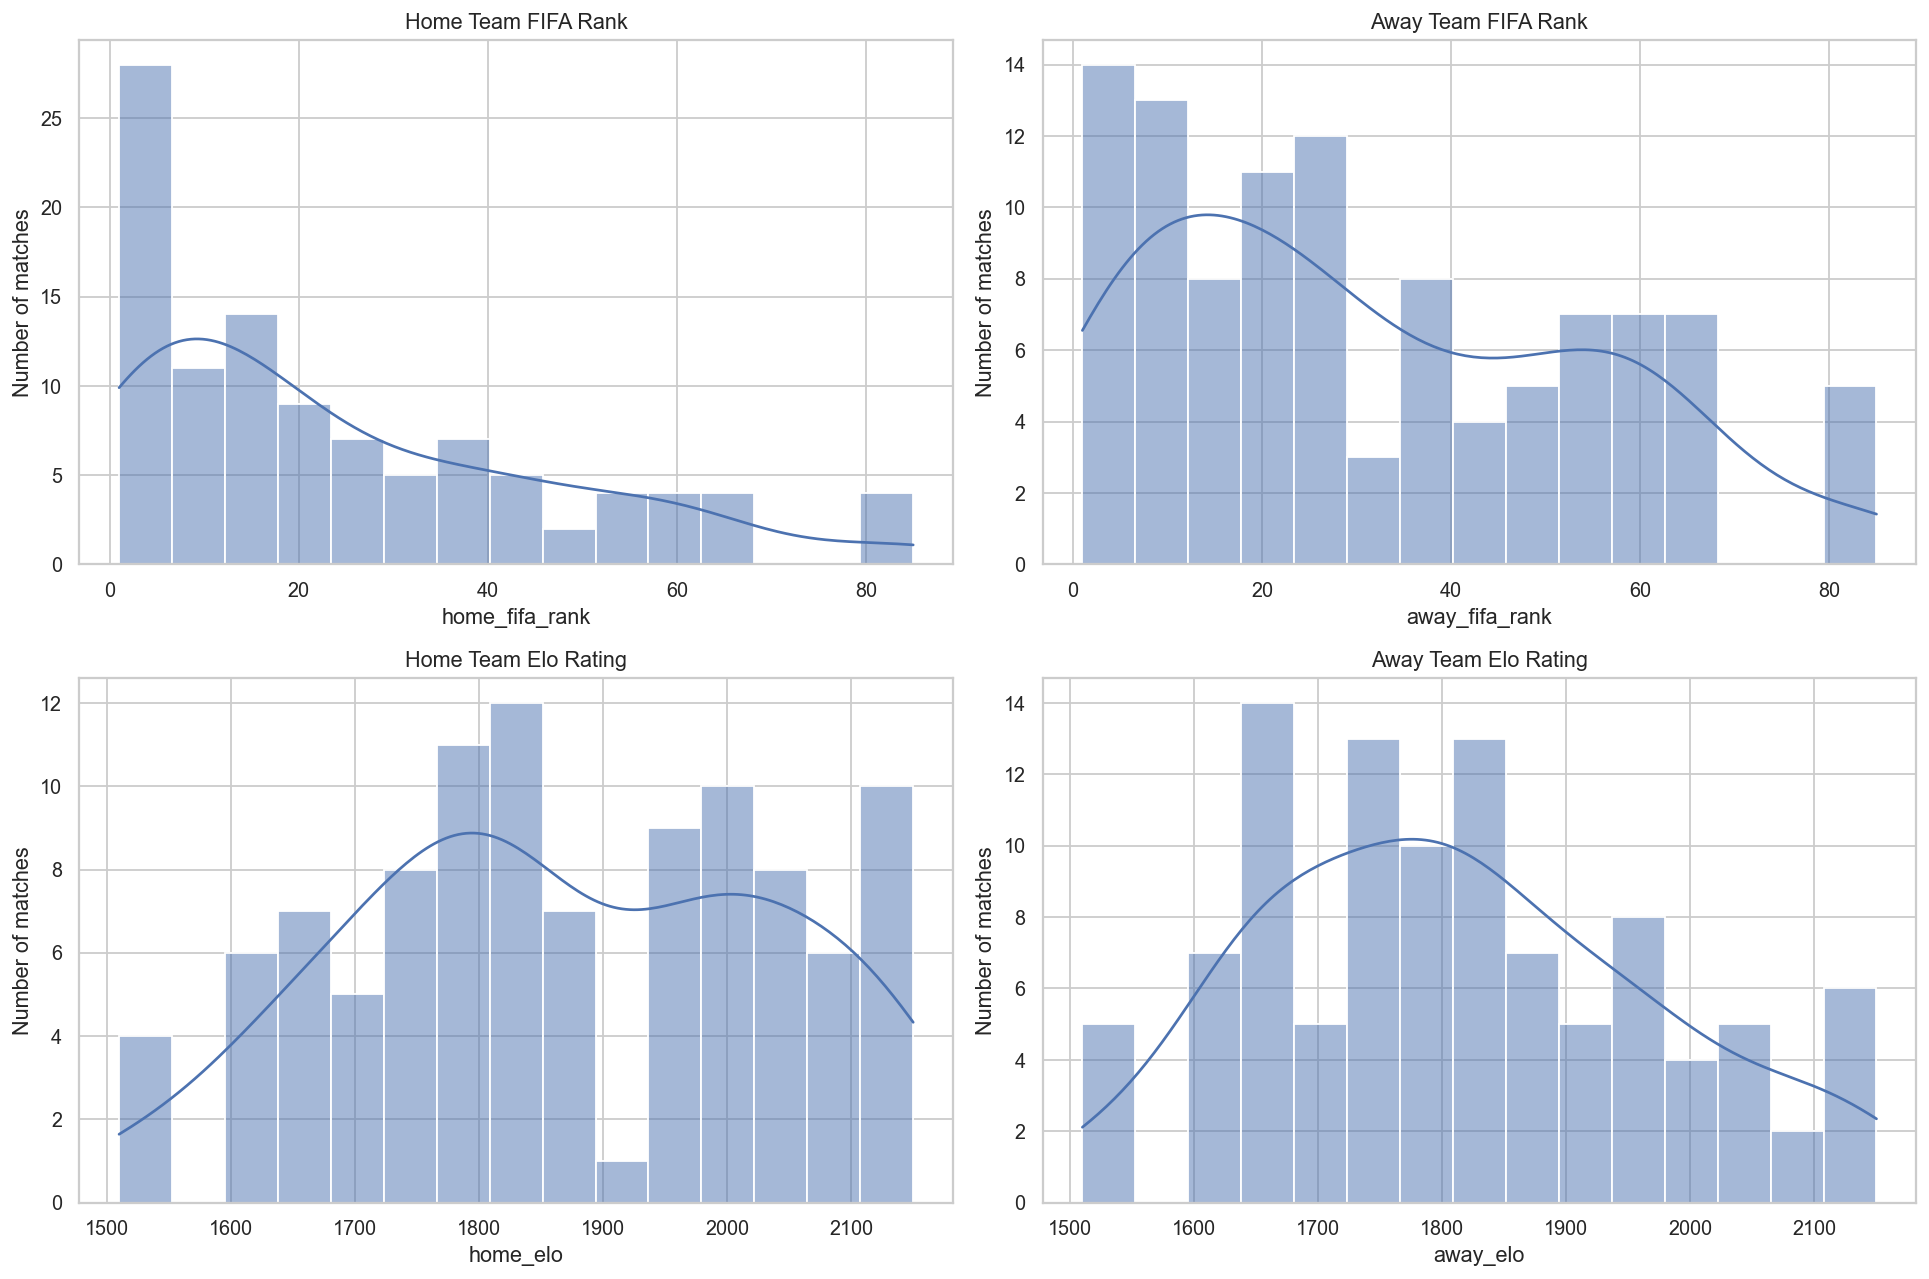

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10), dpi=130)
fields = [
    ('home_fifa_rank', 'Home Team FIFA Rank'),
    ('away_fifa_rank', 'Away Team FIFA Rank'),
    ('home_elo', 'Home Team Elo Rating'),
    ('away_elo', 'Away Team Elo Rating')
]
for ax, (column, label) in zip(axes.flat, fields):
    sns.histplot(data=data, x=column, kde=True, color=sns.color_palette()[0], ax=ax, bins=15)
    ax.set_title(label)
    ax.set_ylabel('Number of matches')

plt.tight_layout()
plt.show()

`Observation:` The distributions show how rankings and ratings vary across matches. Their measurement scales are different, so we will standardise the features using StandardScaler before fitting linear regression.

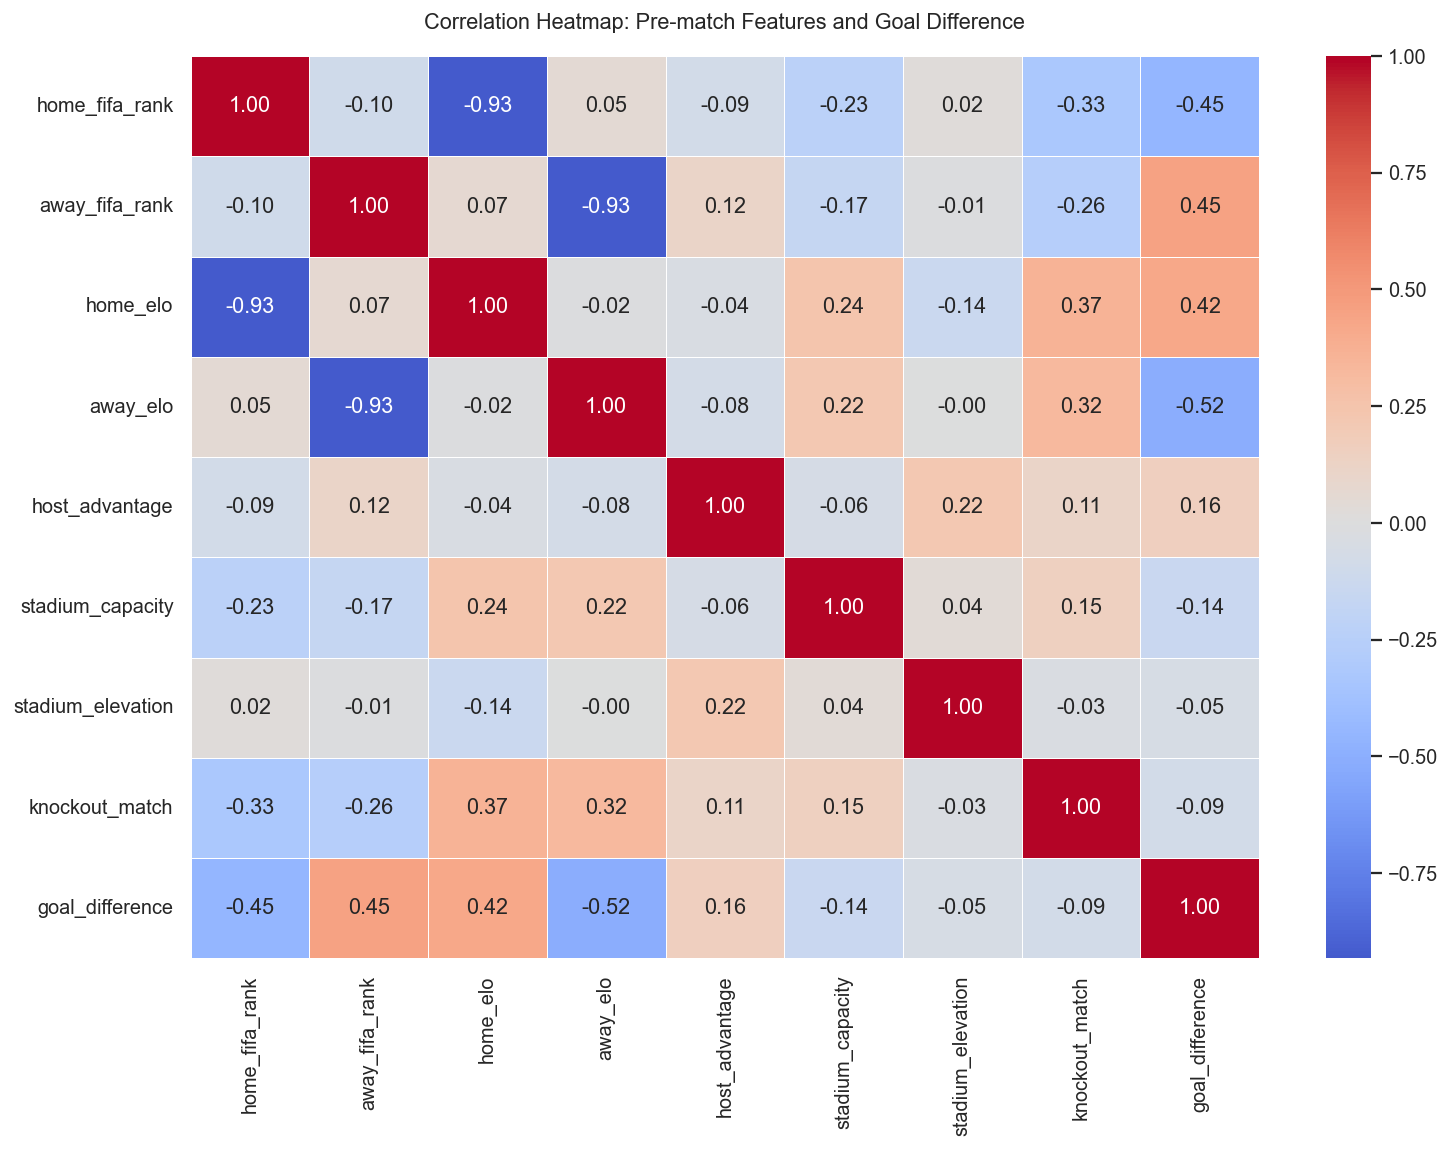

Correlation with goal difference:
goal_difference      1.000000
away_fifa_rank       0.449109
home_elo             0.421235
host_advantage       0.160015
stadium_elevation   -0.050854
knockout_match      -0.086721
stadium_capacity    -0.142969
home_fifa_rank      -0.449667
away_elo            -0.516075
Name: goal_difference, dtype: float64


In [20]:
correlations = data[feature_cols + ['goal_difference']].corr()
plt.figure(figsize=(12, 9), dpi=130)
sns.heatmap(correlations, annot=True, fmt='.2f', linewidths=0.5,
            cmap='coolwarm', center=0)
plt.title('Correlation Heatmap: Pre-match Features and Goal Difference', pad=15)
plt.tight_layout()
plt.show()

print('Correlation with goal difference:')
print(correlations['goal_difference'].sort_values(ascending=False))

`Observation:` This heatmap helps identify the predictors most strongly associated with goal difference. FIFA rankings and Elo ratings describe similar team strength, so they can be correlated with one another. We should therefore be careful when interpreting the individual model coefficients.

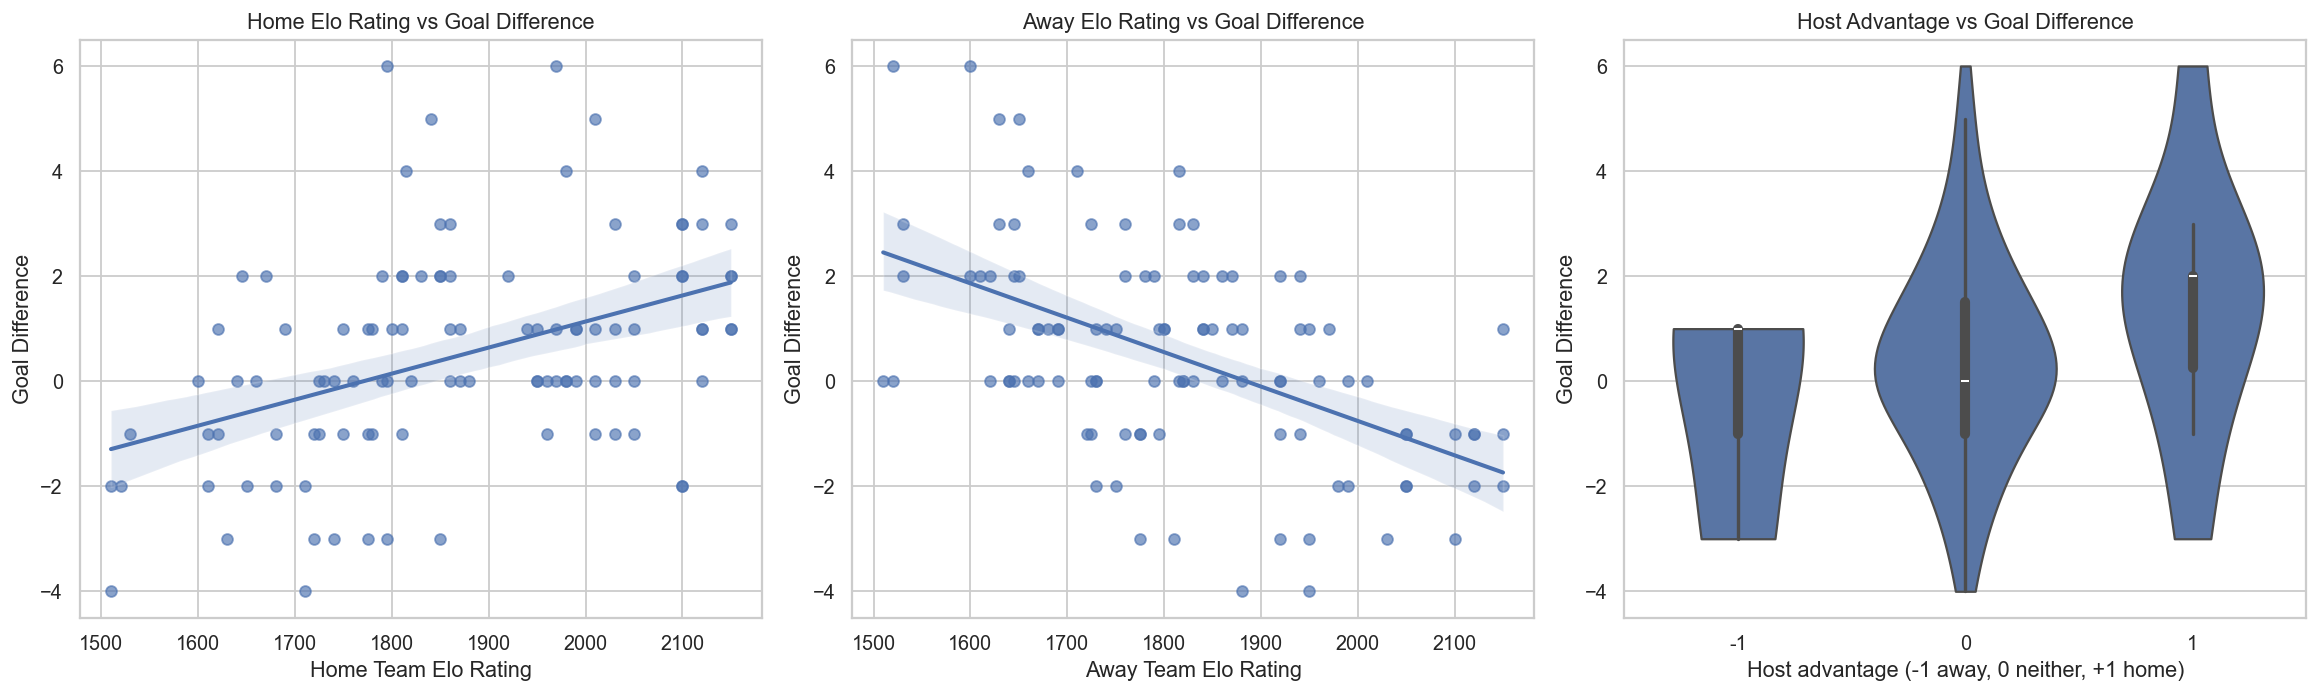

Matches by host advantage:
host_advantage
-1     3
 0    91
 1    10
Name: count, dtype: int64


In [21]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), dpi=130)

sns.regplot(data=plot_data, x='home_elo', y='goal_difference',scatter_kws={'alpha': 0.65}, ax=axes[0])
axes[0].set_title('Home Elo Rating vs Goal Difference')
axes[0].set_xlabel('Home Team Elo Rating')
axes[0].set_ylabel('Goal Difference')

sns.regplot(data=plot_data, x='away_elo', y='goal_difference',scatter_kws={'alpha': 0.65}, ax=axes[1])
axes[1].set_title('Away Elo Rating vs Goal Difference')
axes[1].set_xlabel('Away Team Elo Rating')
axes[1].set_ylabel('Goal Difference')

sns.violinplot(data=plot_data, x='host_advantage', y='goal_difference',inner='box', cut=0, order=[-1, 0, 1], ax=axes[2])
axes[2].set_title('Host Advantage vs Goal Difference')
axes[2].set_xlabel('Host advantage (-1 away, 0 neither, +1 home)')
axes[2].set_ylabel('Goal Difference')

plt.tight_layout()
plt.show()
print('Matches by host advantage:')
print(data['host_advantage'].value_counts().sort_index())

`Observation:` The Elo scatterplots help show whether stronger teams tend to achieve better goal differences. The host-country categories contain different numbers of matches; in particular, very few matches involve the listed away team playing in its own country. Interpret that violin plot cautiously.

## 5. Train-test split

In [23]:
X = data[feature_cols]
y = data['goal_difference']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=145)

print('X train:', X_train.shape)
print('X test: ', X_test.shape)
print('y train:', y_train.shape)
print('y test: ', y_test.shape)
print('\nTraining predictors preview:')
display(X_train.head())

X train: (83, 8)
X test:  (21, 8)
y train: (83,)
y test:  (21,)

Training predictors preview:


,home_fifa_rank,away_fifa_rank,home_elo,away_elo,host_advantage,stadium_capacity,stadium_elevation,knockout_match
5,6,7,2030,1920,0,82500,7,0
4,56,19,1600,1860,0,68500,8,0
15,20,85,1820,1510,0,70240,30,0
28,6,83,2030,1530,0,69796,3,0
9,8,18,1980,1880,0,72220,14,0


## 6. Preprocessing and Model Evaluation

In [24]:
linear_model = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('regressor', LinearRegression())
])

print(linear_model)

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('regressor', LinearRegression())])


In [25]:
linear_model.fit(X_train, y_train)

y_pred_train = linear_model.predict(X_train)
y_pred_test = linear_model.predict(X_test)

print('Linear regression intercept:', round(linear_model.named_steps['regressor'].intercept_, 4))
print('First five predicted goal differences:', np.round(y_pred_test[:5], 2))

Linear regression intercept: 0.4337
First five predicted goal differences: [ 1.59 -0.76  1.34  1.18 -0.01]


In [26]:
def regression_report(actual, predicted):
    return {
        'R2': r2_score(actual, predicted),
        'R2 (%)': 100 * r2_score(actual, predicted),
        'MAE (goals)': mean_absolute_error(actual, predicted),
        'RMSE (goals)': np.sqrt(mean_squared_error(actual, predicted))
    }

train_scores = regression_report(y_train, y_pred_train)
test_scores = regression_report(y_test, y_pred_test)

results = pd.DataFrame({
    'Training': train_scores,
    'Testing': test_scores
}).T

print('Linear Regression performance:')
display(results.round(3))
print(f"Explained variance on test data (R²): {test_scores['R2 (%)']:.2f}%")
print('Note: R² percentage is not classification accuracy.')

Linear Regression performance:


,R2,R2 (%),MAE (goals),RMSE (goals)
Training,0.517,51.728,1.174,1.440
Testing,0.411,41.125,0.987,1.346


Explained variance on test data (R²): 41.13%
Note: R² percentage is not classification accuracy.


In [27]:
baseline = DummyRegressor(strategy='mean')
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)

baseline_scores = regression_report(y_test, baseline_pred)
comparison = pd.DataFrame({
    'Linear Regression': test_scores,
    'Mean Baseline': baseline_scores
}).T
print('Comparison on the SAME 21 test matches:')
display(comparison.round(3))

cv = KFold(n_splits=5, shuffle=True, random_state=145)
cv_r2 = cross_val_score(linear_model, X_train, y_train, cv=cv, scoring='r2')
print('\n5-fold training CV R² scores:', np.round(cv_r2, 3))
print(f'Average training CV R²: {cv_r2.mean():.3f} ({cv_r2.mean() * 100:.2f}%)')

Comparison on the SAME 21 test matches:


,R2,R2 (%),MAE (goals),RMSE (goals)
Linear Regression,0.411,41.125,0.987,1.346
Mean Baseline,-0.018,-1.762,1.421,1.770



5-fold training CV R² scores: [0.268 0.403 0.232 0.217 0.509]
Average training CV R²: 0.326 (32.59%)


`Observation:` The simplified model explains approximately 51.73% of goal-difference variation in the training data and 41.13% in the test data. The test-set MAE is 0.99 goals and RMSE is 1.35 goals. This is a more promising result than the previous version, but we should still be careful because the test set contains only 21 matches. R² is explained variance, not a classification accuracy percentage.

## Actual vs predicted goal difference: best-fit line

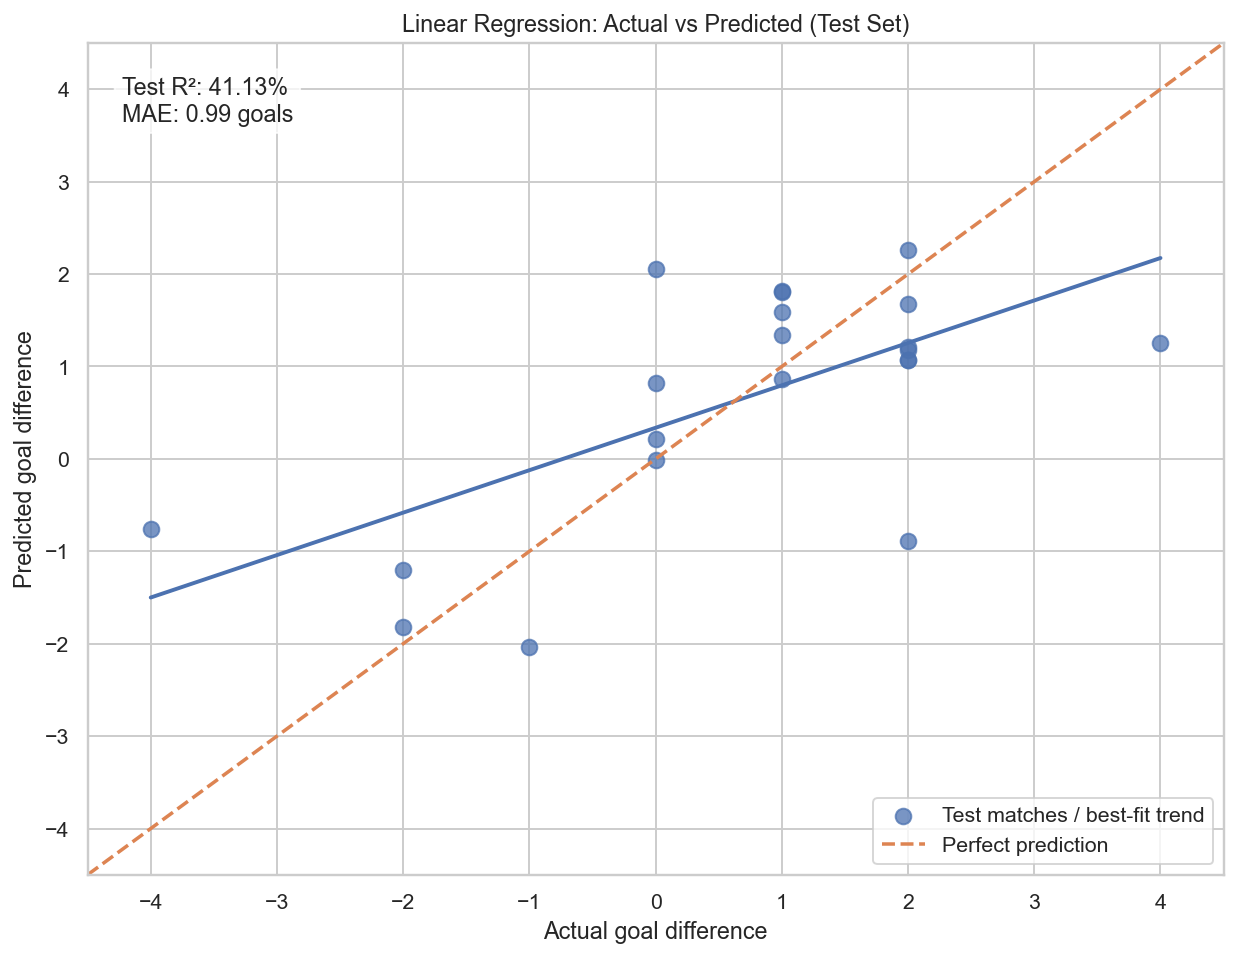

In [28]:
actual = y_test.to_numpy()
predicted = np.asarray(y_pred_test)

fig, ax = plt.subplots(figsize=(9, 7), dpi=140)
sns.regplot(x=actual, y=predicted, ax=ax,scatter_kws={'s': 65, 'alpha': 0.75},line_kws={'linewidth': 2}, ci=None,label='Test matches / best-fit trend')

lower = min(actual.min(), predicted.min()) - 0.5
upper = max(actual.max(), predicted.max()) + 0.5
ax.plot([lower, upper], [lower, upper], '--', linewidth=1.8,label='Perfect prediction')
ax.set(xlim=(lower, upper), ylim=(lower, upper),
       xlabel='Actual goal difference',
       ylabel='Predicted goal difference',
       title='Linear Regression: Actual vs Predicted (Test Set)')
ax.text(0.03, 0.96,
        f"Test R²: {test_scores['R2 (%)']:.2f}%\nMAE: {test_scores['MAE (goals)']:.2f} goals",
        transform=ax.transAxes, va='top',
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.75))
ax.legend(loc='lower right')

plt.tight_layout()
plt.show()

`Intuition:` Points lying closer to the diagonal represent more accurate predictions. The distance away from this line shows prediction errors. The fitted trend line helps visualise the overall relationship, but R², MAE and RMSE are the actual performance measures.

## Residual analysis

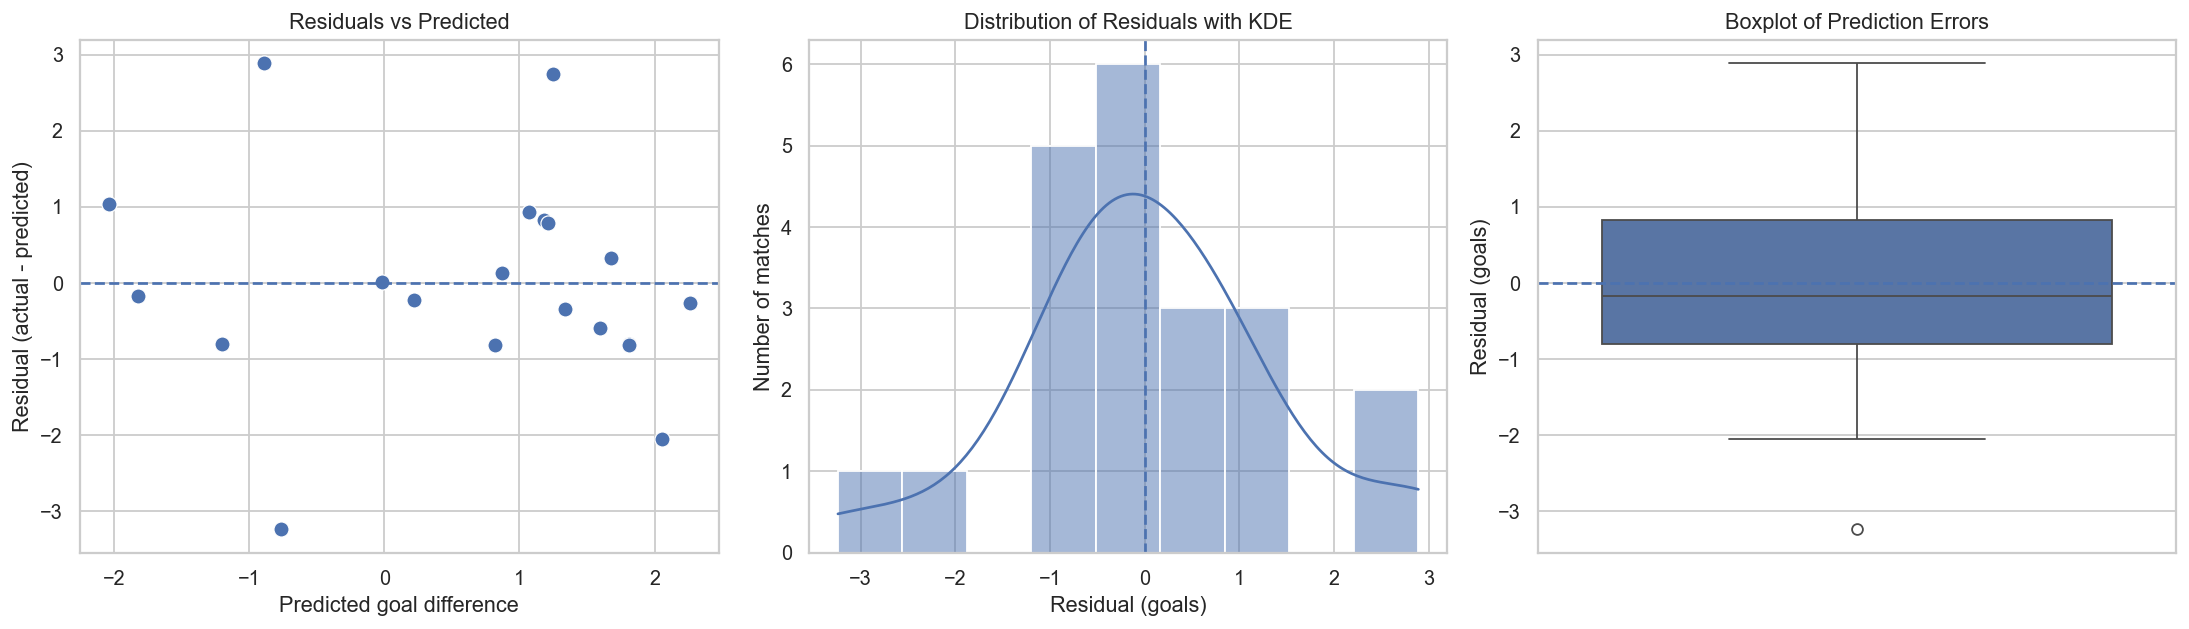

In [29]:
residuals = actual - predicted

fig, axes = plt.subplots(1, 3, figsize=(17, 5), dpi=130)

sns.scatterplot(x=predicted, y=residuals, ax=axes[0], s=70)
axes[0].axhline(0, linestyle='--', linewidth=1.5)
axes[0].set(title='Residuals vs Predicted',
            xlabel='Predicted goal difference', ylabel='Residual (actual - predicted)')

sns.histplot(x=residuals, kde=True, bins=9, color=sns.color_palette()[0], ax=axes[1])
axes[1].axvline(0, linestyle='--', linewidth=1.5)
axes[1].set(title='Distribution of Residuals with KDE',
            xlabel='Residual (goals)', ylabel='Number of matches')

sns.boxplot(y=residuals, color=sns.color_palette()[0], ax=axes[2])
axes[2].axhline(0, linestyle='--', linewidth=1.5)
axes[2].set(title='Boxplot of Prediction Errors', ylabel='Residual (goals)')

plt.tight_layout()
plt.show()

## Example predictions and export

In [30]:
test_predictions = pd.DataFrame({
    'match_id': data.loc[X_test.index, 'match_id'].to_numpy(),
    'actual_goal_difference': actual,
    'predicted_goal_difference': np.round(predicted, 3),
    'residual': np.round(residuals, 3)
}).sort_values('match_id').reset_index(drop=True)

display(test_predictions.head(10))

test_predictions.to_csv('linear_regression_2_1_simplified_test_predictions.csv', index=False)
results.round(6).to_csv('linear_regression_2_1_simplified_metrics.csv', index_label='Dataset')
print('Saved the 104-row modelling CSV, metrics CSV and test predictions CSV.')

,match_id,actual_goal_difference,predicted_goal_difference,residual
0,1,2,1.070,0.930
1,2,1,0.869,0.131
2,25,1,1.594,-0.594
3,31,2,1.676,0.324
4,35,4,1.251,2.749
5,36,-4,-0.761,-3.239
6,43,2,2.259,-0.259
7,46,1,1.810,-0.810
8,47,0,2.053,-2.053
9,58,-2,-1.200,-0.800


Saved the 104-row modelling CSV, metrics CSV and test predictions CSV.
